# Berlin Urban Flood — Phase 4: U-Net on **real Berlin rasters**

**Purpose:** Check that the *original-style Berlin U-Net architecture* can train and predict on **actual 13-channel Berlin inputs and TELEMAC-2D labels**. This is a **technical real-data pilot**, **not** a reproduction of Seleem et al.'s full results, **not** a transfer result for Ho Chi Minh City.

**Best way to run:** in the **same active Kaggle Phase 3 session**, copy these code cells **in order** to the bottom of your successful Phase 3 notebook. This reuses 12 aligned predictor TIFFs in `/kaggle/working` and the six water-depth TIFFs in `/kaggle/tmp`. **Do not restart the Phase 3 session.** If using this notebook as a *new Kaggle notebook*, you must first attach a Kaggle Dataset containing **all 12 aligned predictor rasters** and **six SA1 rainfall depth rasters**. The RF `.joblib` and metric `.csv` files alone are **not sufficient**. No 20.8 GB predictor re-download is attempted.

**Kaggle:** **DO NOT change CPU → GPU in the current Phase 3 session before saving the data**: changing Accelerator restarts the session and may destroy the scratch/working cache. This tiny verification can run on CPU (slower). To use a T4 GPU in a new session, first persist and attach the 12 predictors + six targets as Kaggle input; then import this notebook. Internet can be Off once the data are attached. If data are missing, the notebook will stop with a clear message. **Default `SMOKE_ONLY=True`** uses 2 training spatial patches × 4 rain scenarios (8 training examples), 1 validation patch at 90 mm, and 1 one-time test patch at 100 mm; `EPOCHS=1`, batch size 1. This is deliberately tiny to check runnability even on CPU. After PASS, set `SMOKE_ONLY=False` for all 27/9 spatial tiles and more epochs if desired.

[Original published code](https://github.com/omarseleem92/Machine_learning_for_urban_flooding/tree/main/Code/Convolutional%20neural%20network) · [Berlin data used for this pilot](https://zenodo.org/records/7221058) · [Paper](https://doi.org/10.5194/nhess-23-809-2023)

**Differences from paper**: Spatial tile sampling on SA1 only, explicit raster alignment/NoData masking, train-only robust scaling, 1-epoch test mode, reduced learning rate, and a different experimental split. These adaptations are recorded in the summary. For valid published-score comparison, the paper's preprocessing, SA1+SA2 splits, and test protocol must be reconstructed separately.

In [1]:

from pathlib import Path

root = Path("/kaggle/input")

predictors = list(root.rglob("*_SA1.tif"))
targets = list(root.rglob("WD_*mm.tif"))

print("Spatial predictors:", len(predictors))
print("Water-depth targets:", len(targets))

assert len(predictors) == 12, "Missing predictors"
assert len(targets) == 6, "Missing targets"

print("DATASET READY FOR PHASE 4")


Spatial predictors: 12
Water-depth targets: 6
DATASET READY FOR PHASE 4


## 1 — Configuration (no download)

This notebook **does not assume access to Python variables from Phase 3**; it discovers the saved raster files directly. That makes it safe even if a cell was rerun, *provided the TIFF files still exist*.

In [2]:
from pathlib import Path
import os, sys, json, time, gc, shutil
from contextlib import ExitStack
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT
from rasterio.windows import Window
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED=42
SMOKE_ONLY=True  # tiny engineering check (8 training examples); False = 27 train and 9 held-out tiles
EPOCHS=1 if SMOKE_ONLY else 5
BATCH_SIZE=1
TRAIN_RAIN=(40,60,80,120)
VAL_RAIN=90
TEST_RAIN=100
ALL_RAIN=tuple(sorted(set(TRAIN_RAIN+(VAL_RAIN,TEST_RAIN))))
RAINFALL_CENTER=float(np.mean(TRAIN_RAIN))
RAINFALL_SCALE=float(np.std(TRAIN_RAIN))
MIN_VALID_PIXELS=200
IMG_SIZE=256

FEATURES=[
  'CN.tif','Cos_Aspect.tif','Curvature.tif',
  'DEM_berlin_boundary.tif','DEM_depth_1m_clip.tif','DEM_L.tif',
  'flow_acc_comb_nodata_clipped.tif','roughness_final_berlin.tif',
  'Sin_Aspect.tif','Slope_degree.tif','TPI_nan.tif',
  'TWI_Low_pass_filter_berlin_boundary.tif'
]
FEATURE_LABELS=[Path(f).stem for f in FEATURES]+['Rainfall_mm']
OUT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/tmp/berlin_phase4')
OUT.mkdir(parents=True,exist_ok=True)
np.random.seed(SEED)
print('Output:',OUT,'| Smoke mode:',SMOKE_ONLY,'| epochs:',EPOCHS)
print('Python:',sys.version.split()[0],'| rasterio:',rasterio.__version__)
print('Free working disk GiB:',round(shutil.disk_usage(OUT).free/2**30,2))


Output: /kaggle/working | Smoke mode: True | epochs: 1
Python: 3.13.15 | rasterio: 1.5.1
Free working disk GiB: 19.5


## 2 — Find Phase 3 raster cache / attached Kaggle Dataset

Expected **predictor folder**: `berlin_sa1_aligned_predictors/` with 12 `*_SA1.tif` files. Expected **target folder**: `.../SA1/WD_40mm.tif`, etc., or `berlin_sa1_targets/WD_40mm.tif`. Do **not** proceed with only RF model files. The notebook checks the actual raster grids and tags.

In [6]:

from pathlib import Path

DATA_ROOT = Path("/kaggle/input")

PRED_DIR = Path("/kaggle/working/berlin_sa1_aligned_predictors")
TARGET_DIR = Path("/kaggle/working/berlin_sa1_targets")

PRED_DIR.mkdir(parents=True, exist_ok=True)
TARGET_DIR.mkdir(parents=True, exist_ok=True)

def link_file(filename, destination):
    matches = list(DATA_ROOT.rglob(filename))
    matches = [p for p in matches if p.is_file()]

    assert len(matches) == 1, (
        f"Expected one {filename}, found {len(matches)}"
    )

    source = matches[0].resolve()
    target = destination / filename

    if target.is_symlink() and not target.exists():
        target.unlink()

    if not target.exists():
        target.symlink_to(source)

    return target

# Link 12 spatial features
for feature in FEATURES:
    name = Path(feature).stem + "_SA1.tif"
    link_file(name, PRED_DIR)

# Link 6 water-depth targets
for rain in ALL_RAIN:
    link_file(f"WD_{rain}mm.tif", TARGET_DIR)

print("Predictors:", len(list(PRED_DIR.glob("*.tif"))))
print("Targets:", len(list(TARGET_DIR.glob("*.tif"))))
print("DATA PATHS READY")


Predictors: 12
Targets: 6
DATA PATHS READY


In [7]:
ROOTS=[Path('/kaggle/working'),Path('/kaggle/input'),Path('/kaggle/tmp')]
# Find the first folder with all 12 expected aligned feature files.
search_dirs=[]
for root in ROOTS:
    if not root.exists(): continue
    direct=root/'berlin_sa1_aligned_predictors'
    if direct.is_dir(): search_dirs.append(direct)
    # Kaggle datasets may be nested one/two levels under /kaggle/input.
    if root.name=='input':
        search_dirs.extend(root.glob('*/berlin_sa1_aligned_predictors'))
        search_dirs.extend(root.glob('*/*/berlin_sa1_aligned_predictors'))

crop_candidates=[(d,sum((d/(Path(f).stem+'_SA1.tif')).is_file() for f in FEATURES))
                 for d in search_dirs if d.is_dir()]
print('Predictor directories:',[(str(d),n) for d,n in crop_candidates])
complete=[d for d,n in crop_candidates if n==12]
if not complete:
    raise FileNotFoundError(
        'No complete 12-feature aligned raster directory found. '
        'Use the SAME active Phase 3 notebook/session, or attach a Kaggle Dataset '
        'containing berlin_sa1_aligned_predictors/*.tif. '
        f'Candidates found: {[(str(d),n) for d,n in crop_candidates]}')
CROPS=complete[0]

# Phase 3 stores targets in the scratch directory, while a saved dataset can store them elsewhere.
def find_target(rain):
    name=f'WD_{rain}mm.tif'
    direct=[
        Path('/kaggle/tmp/berlin_phase3/Water_depth_TELEMAC_2D/SA1')/name,
        Path('/kaggle/working/berlin_sa1_targets')/name,
        Path('/kaggle/working/berlin_phase4_data/berlin_sa1_targets')/name,
    ]
    for root in ROOTS:
        if not root.is_dir():continue
        if root.name=='input':
            direct += list(root.glob('*/berlin_sa1_targets/'+name))
            direct += list(root.glob('*/*/berlin_sa1_targets/'+name))
            direct += list(root.glob('*/SA1/'+name))
            direct += list(root.glob('*/*/SA1/'+name))
    for p in direct:
        if p.is_file():return p
    return None

TARGET_FILES={r:find_target(r) for r in ALL_RAIN}
print('CROPS:',CROPS)
for r,p in TARGET_FILES.items(): print('Water depth',r,'mm ->',p)
missing=[r for r,p in TARGET_FILES.items() if p is None]
if missing:
    raise FileNotFoundError(
        f'Missing target scenarios: {missing}. In the original Phase 3 session, '
        'check /kaggle/tmp/berlin_phase3/Water_depth_TELEMAC_2D/SA1. '
        'For a new notebook, first save/attach these six target TIFFs in a Kaggle Dataset. '
        'Do not rerun 20GB predictor download.')

REF=TARGET_FILES[60]
with rasterio.open(REF) as ref:
    GRID=dict(crs=ref.crs,transform=ref.transform,width=ref.width,height=ref.height,
              resolution=tuple(ref.res))
assert GRID['crs'] is not None
assumed_crs=[]
for f in FEATURES:
    path=CROPS/(Path(f).stem+'_SA1.tif')
    with rasterio.open(path) as src:
        assert (src.width,src.height)==(GRID['width'],GRID['height']),f'Grid size mismatch: {f}'
        assert src.crs==GRID['crs'],f'CRS mismatch: {f}'
        assert src.transform.almost_equals(GRID['transform']),f'Transform mismatch: {f}'
        if src.tags().get('source_crs_original')=='missing': assumed_crs.append(f)
print('PASS: all 12 predictors aligned to',GRID['width'],GRID['height'],GRID['crs'])
if assumed_crs: print('WARNING, provisional CRS assumptions made in Phase 3:',assumed_crs)

# Save target rasters to the working directory for future Kaggle datasets, if scratch files exist.
PERSIST_TARGETS_TO_WORKING=True
if PERSIST_TARGETS_TO_WORKING:
    td=OUT/'berlin_sa1_targets';td.mkdir(parents=True,exist_ok=True)
    for r,p in TARGET_FILES.items():
        dest=td/p.name
        if not dest.is_file() or dest.stat().st_size!=p.stat().st_size:
            if p.resolve()!=dest.resolve():
                shutil.copy2(p,dest)
                print('Preserved target in /kaggle/working:',dest.name)
    print('Target cache persisted at:',td)


Predictor directories: [('/kaggle/working/berlin_sa1_aligned_predictors', 12)]
CROPS: /kaggle/working/berlin_sa1_aligned_predictors
Water depth 40 mm -> /kaggle/working/berlin_sa1_targets/WD_40mm.tif
Water depth 60 mm -> /kaggle/working/berlin_sa1_targets/WD_60mm.tif
Water depth 80 mm -> /kaggle/working/berlin_sa1_targets/WD_80mm.tif
Water depth 90 mm -> /kaggle/working/berlin_sa1_targets/WD_90mm.tif
Water depth 100 mm -> /kaggle/working/berlin_sa1_targets/WD_100mm.tif
Water depth 120 mm -> /kaggle/working/berlin_sa1_targets/WD_120mm.tif
PASS: all 12 predictors aligned to 3253 3577 EPSG:25833
WARNING, provisional CRS assumptions made in Phase 3: ['flow_acc_comb_nodata_clipped.tif']
Target cache persisted at: /kaggle/working/berlin_sa1_targets


## 3 — Build spatially disjoint 256×256 patches (same SA1 split as Phase 3)

- **Training**: spatial training tiles at 40/60/80/120 mm rainfall.
- **Validation**: held-out spatial tiles at 90 mm rainfall.
- **Test**: the same held-out spatial tiles at **100 mm**, evaluated only once after training. Therefore validation and test are *not fully independent geographically*; do not claim full generalization.
- Phase 4 uses **full patches** instead of Phase 3's 700 randomly sampled pixels per tile. Metrics from Phase 3 and 4 are **not directly comparable**.
- Pixels lacking any feature or target are **masked** from training/evaluation. They are *not interpreted as dry pixels*.

In [8]:
N_TILES_AXIS=6
all_tiles=[]
for iy in range(N_TILES_AXIS):
    for ix in range(N_TILES_AXIS):
        row0=min(int((iy+.5)*GRID['height']/N_TILES_AXIS),max(0,GRID['height']-IMG_SIZE))
        col0=min(int((ix+.5)*GRID['width']/N_TILES_AXIS),max(0,GRID['width']-IMG_SIZE))
        all_tiles.append((iy*N_TILES_AXIS+ix,Window(col0,row0,IMG_SIZE,IMG_SIZE)))
assert len(all_tiles)==36

manifest=OUT/'berlin_phase3_experiment.json'
if manifest.is_file():
    previous=json.loads(manifest.read_text())
    train_ids=[int(i) for i in previous['spatial_train_tiles']]
    heldout_ids=[int(i) for i in previous['spatial_val_test_tiles']]
    assert previous['features']==FEATURE_LABELS, 'Feature order differs from the Phase 3 experiment'
    print('Reused Phase 3 split manifest:',manifest)
else:
    train_ids,heldout_ids=train_test_split(list(range(36)),test_size=.25,random_state=SEED)
    train_ids=sorted(map(int,train_ids));heldout_ids=sorted(map(int,heldout_ids))
    print('WARNING: Phase 3 manifest absent; reconstructed split from seed=42')
assert set(train_ids).isdisjoint(heldout_ids)
if SMOKE_ONLY:
    train_ids=sorted(train_ids)[:2]
    heldout_ids=sorted(heldout_ids)[:1]
print('Training tile IDs:',train_ids)
print('Held-out tile IDs:',heldout_ids)
use_tiles={idx:win for idx,win in all_tiles if idx in set(train_ids)|set(heldout_ids)}

# Each source is opened only once. WarpedVRT aligns target rasters onto the Phase 3 reference grid.
SPATIAL={};DEPTH={};VALID_X={}
with ExitStack() as stack:
    spatial_src=[stack.enter_context(rasterio.open(CROPS/(Path(f).stem+'_SA1.tif'))) for f in FEATURES]
    target_src={r:stack.enter_context(rasterio.open(TARGET_FILES[r])) for r in ALL_RAIN}
    target_vrt={r:stack.enter_context(WarpedVRT(s,crs=GRID['crs'],transform=GRID['transform'],
                                  width=GRID['width'],height=GRID['height'],dtype='float32',
                                  nodata=np.nan,resampling=Resampling.nearest))
                for r,s in target_src.items()}
    for tile,win in use_tiles.items():
        channels=[s.read(1,window=win,masked=True).astype('float32').filled(np.nan)
                  for s in spatial_src]
        x=np.stack(channels,axis=-1).astype('float32')
        assert x.shape==(256,256,12)
        SPATIAL[tile]=x
        VALID_X[tile]=np.isfinite(x).all(axis=-1)
        for rain in (TRAIN_RAIN if tile in train_ids else (VAL_RAIN,TEST_RAIN)):
            y=target_vrt[rain].read(1,window=win,masked=True).astype('float32').filled(np.nan)
            assert y.shape==(256,256)
            DEPTH[(tile,rain)]=y

RECORDS={}
for split,tile_ids,rains in [('train',train_ids,TRAIN_RAIN),('validation',heldout_ids,(VAL_RAIN,)),
                            ('test',heldout_ids,(TEST_RAIN,))]:
    records=[]
    for tid in tile_ids:
        for rain in rains:
            y=DEPTH[(tid,rain)]
            valid=VALID_X[tid]&np.isfinite(y)&(y>=0)
            n=int(valid.sum())
            if n<MIN_VALID_PIXELS:
                print('SKIPPED',split,'tile',tid,'rain',rain,'only',n,'valid pixels')
                continue
            records.append(dict(split=split,tile_id=int(tid),rain_mm=int(rain),
                                valid_pixels=n,valid_fraction=float(valid.mean()),
                                wet_fraction=float((y[valid]>=0.1).mean())))
    if not records:raise RuntimeError('No valid patches for '+split+'; inspect NoData and spatial alignment')
    RECORDS[split]=records
    print(split,':',len(records),'patches, mean valid fraction',
          round(np.mean([x['valid_fraction'] for x in records]),4),
          'mean wet fraction',round(np.mean([x['wet_fraction'] for x in records]),4))

assert {r['tile_id'] for r in RECORDS['train']}.isdisjoint({r['tile_id'] for r in RECORDS['validation']})
assert {r['tile_id'] for r in RECORDS['train']}.isdisjoint({r['tile_id'] for r in RECORDS['test']})
pd.DataFrame(sum(RECORDS.values(),[])).to_csv(OUT/'berlin_phase4_patch_manifest.csv',index=False)
print('PASS: real Berlin tiles and water-depth labels loaded')


Training tile IDs: [0, 1]
Held-out tile IDs: [8]
train : 8 patches, mean valid fraction 1.0 mean wet fraction 0.0539
validation : 1 patches, mean valid fraction 1.0 mean wet fraction 0.0461
test : 1 patches, mean valid fraction 1.0 mean wet fraction 0.051
PASS: real Berlin tiles and water-depth labels loaded


## 4 — Normalize **training features only** (documented adaptation)

The original public notebook does not provide a fully portable preprocessing pipeline. Here the 12 spatial features are robustly standardized using **training tiles only** (median/IQR), clipped to `[-6,6]`, and the rainfall channel is scaled from the four training rain levels. This stabilizes the first run, but **is not a paper-identical preprocessing choice**. NoData feature pixels are filled with zero **after** scaling and omitted by loss weights.

In [10]:
rng=np.random.default_rng(SEED)
samples=[]
for tid in train_ids:
    x=SPATIAL[tid]
    valid_idx=np.flatnonzero(VALID_X[tid])
    if not len(valid_idx): continue
    take=rng.choice(valid_idx,size=min(4000,len(valid_idx)),replace=False)
    samples.append(x.reshape(-1,12)[take])
assert samples,'Cannot normalize: no valid training feature pixels'
train_feature_sample=np.concatenate(samples,axis=0).astype('float64')
q25,q50,q75=np.percentile(train_feature_sample,[25,50,75],axis=0)
scales=(q75-q25)/1.349
fallback=np.std(train_feature_sample,axis=0)
scales=np.where(scales>1e-8,scales,np.where(fallback>1e-8,fallback,1.0))
centers=q50.astype('float32')
scales=scales.astype('float32')
assert np.isfinite(centers).all() and np.isfinite(scales).all()

# Convert one (tile, rain) into (13-channel input, depth target, pixel-wise validity weight)
def make_sample(rec):
    tid=rec['tile_id'];rain=rec['rain_mm']
    spatial=SPATIAL[tid]
    z=(spatial-centers[None,None,:])/scales[None,None,:]
    z=np.clip(z,-6,6)
    z=np.where(np.isfinite(z),z,0).astype('float32')
    x=np.empty((IMG_SIZE,IMG_SIZE,13),dtype='float32')
    x[...,:12]=z
    x[...,12]=(rain-RAINFALL_CENTER)/max(RAINFALL_SCALE,1.0)
    raw_y=DEPTH[(tid,rain)]
    valid=VALID_X[tid]&np.isfinite(raw_y)&(raw_y>=0)
    y=np.where(valid,raw_y,0).astype('float32')[...,None]
    w=valid.astype('float32')[...,None]
    assert x.shape==(256,256,13) and y.shape==(256,256,1)
    assert np.isfinite(x).all() and np.isfinite(y).all()
    return x,y,w

x0,y0,w0=make_sample(RECORDS['train'][0])
print('First training patch:',x0.shape,y0.shape,w0.shape,'valid pixels',int(w0.sum()))
print('Scaled x range:',round(float(x0.min()),3),round(float(x0.max()),3),
      'target max:',float(y0.max()))
NORM=dict(spatial_feature_order=FEATURE_LABELS[:-1],
          medians=centers.tolist(),scales=scales.tolist(),spatial_clip=[-6,6],
          rainfall_center_mm=RAINFALL_CENTER,rainfall_scale_mm=RAINFALL_SCALE,
          invalid_feature_fill_after_scaling=0,invalid_target_masked=True,
          fitted_using='training spatial tiles only')
(OUT/'berlin_phase4_normalization.json').write_text(json.dumps(NORM,indent=2))


First training patch: (256, 256, 13) (256, 256, 1) (256, 256, 1) valid pixels 65536
Scaled x range: -6.0 6.0 target max: 0.2566511631011963


1144

## 5 — Build **original-style U-Net** (13 input channels → one depth map)

Replicates the structural choices in the public `U-Net.SA1&2.ipynb`: 32→64→128→256→512 filters, pairs of Conv2D + BatchNorm + LeakyReLU + Dropout(0.5), average pooling, transposed-convolution skip decoder, **linear regression output**, Adam, MSE. Updated `LeakyReLU` and checkpoint API for current TensorFlow/Keras. Runs on one GPU; using T4×2 does not automatically split data across both GPUs.

In [11]:
import tensorflow as tf
from tensorflow.keras import layers as L
try:
    for g in tf.config.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(g,True)
except RuntimeError as e:
    print('GPU memory growth not changed:',e)
print('TensorFlow:',tf.__version__)
print('Available GPUs:',tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: no GPU detected; enable a GPU Accelerator in Kaggle before training.')
tf.keras.utils.set_random_seed(SEED)

def conv_block(x,n_filters):
    for _ in range(2):
        x=L.Conv2D(n_filters,3,padding='same',kernel_initializer='he_normal',use_bias=False)(x)
        x=L.BatchNormalization()(x)
        x=L.LeakyReLU(negative_slope=0.2)(x)
        x=L.Dropout(0.5)(x)
    return x

def build_original_style_unet():
    inputs=L.Input((256,256,13),name='Berlin_13_channels')
    x=inputs;skip=[]
    for filters in (32,64,128,256):
        x=conv_block(x,filters)
        skip.append(x)
        x=L.AveragePooling2D((2,2))(x)
    x=conv_block(x,512)
    for filters,s in zip((256,128,64,32),reversed(skip)):
        x=L.Conv2DTranspose(filters,2,strides=2,padding='same')(x)
        x=L.Concatenate()([x,s])
        x=conv_block(x,filters)
    return tf.keras.Model(inputs,L.Conv2D(1,1,padding='same',dtype='float32')(x),
                          name='Berlin_U_Net_original_style')

model=build_original_style_unet()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='mse',weighted_metrics=[tf.keras.metrics.RootMeanSquaredError(name='valid_rmse')])
print('Input:',model.input_shape,'Output:',model.output_shape,
      'parameters:',model.count_params())
assert model.input_shape[1:]==(256,256,13)
assert model.output_shape[1:]==(256,256,1)


TensorFlow: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1793643254.256546      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793643254.261012      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Input: (None, 256, 256, 13) Output: (None, 256, 256, 1) parameters: 7771809


## 6 — Train: **1 epoch** on real Berlin data by default

The generator produces real patches and per-pixel validity weights. It doesn't load all 3,253×3,577×13 rasters into RAM. NoData pixels do not influence the training loss. `berlin_phase4_unet_best.keras` records the best validation epoch, and `berlin_phase4_history.csv` stores the training log.

In [12]:
def dataset_for(part,shuffle=False):
    records=list(RECORDS[part])
    def stream():
        for rec in records:
            yield make_sample(rec)
    shape=tf.TensorSpec((256,256,13),tf.float32)
    scalar_map=tf.TensorSpec((256,256,1),tf.float32)
    ds=tf.data.Dataset.from_generator(stream,output_signature=(shape,scalar_map,scalar_map))
    if shuffle:ds=ds.shuffle(len(records),seed=SEED,reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(1)

train_ds=dataset_for('train',True)
val_ds=dataset_for('validation')
checkpointer=tf.keras.callbacks.ModelCheckpoint(
    str(OUT/'berlin_phase4_unet_best.keras'),monitor='val_loss',mode='min',
    save_best_only=True,verbose=1)
logger=tf.keras.callbacks.CSVLogger(str(OUT/'berlin_phase4_history.csv'))
callbacks=[checkpointer,logger]
if not SMOKE_ONLY:
    callbacks.append(tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,
                                                        restore_best_weights=True))
start=time.time()
history=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,callbacks=callbacks,verbose=2)
training_seconds=time.time()-start
print('PASS: trained U-Net on REAL Berlin flood-depth data.')
print('Training seconds:',round(training_seconds,1))
print('Best model:',OUT/'berlin_phase4_unet_best.keras')


2026-11-02 18:15:55.203130: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 18:15:55.398914: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 18:15:56.919709: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 18:15:57.223830: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-02 18:15:58.004152: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 2.16585, saving model to /kaggle/working/berlin_phase4_unet_best.keras

Epoch 1: finished saving model to /kaggle/working/berlin_phase4_unet_best.keras
8/8 - 39s - 5s/step - loss: 2.7244 - val_loss: 2.1659 - val_valid_rmse: 1.4717 - valid_rmse: 1.6506
PASS: trained U-Net on REAL Berlin flood-depth data.
Training seconds: 39.4
Best model: /kaggle/working/berlin_phase4_unet_best.keras


## 7 — Evaluate full valid pixels, including wet-area metrics

Evaluation uses **all valid pixels in each selected 256×256 patch**, unlike Phase 3's RF evaluation on 700 sampled pixels per tile. Predicted negative depth is clipped at zero *for evaluation*, and this is recorded. The `TEST_RAIN=100` scenario is evaluated only after training completes. Do not tune using these test results.

In [13]:
def compute_metrics(true,pred):
    true=np.asarray(true,dtype='float64');pred=np.asarray(pred,dtype='float64')
    if len(true)==0:raise ValueError('No valid evaluation pixels')
    wet=true>=0.1;forecast=pred>=0.1
    tp=int((wet & forecast).sum());fp=int((~wet & forecast).sum());fn=int((wet & ~forecast).sum())
    return dict(rmse=float(np.sqrt(np.mean((true-pred)**2))),
                mae=float(np.mean(np.abs(true-pred))),
                r2_or_nse=float(r2_score(true,pred)) if np.var(true)>1e-12 else None,
                csi_10cm=float(tp/(tp+fp+fn)) if tp+fp+fn else None,
                wet_pixel_rmse=float(np.sqrt(np.mean((true[wet]-pred[wet])**2))) if wet.any() else None,
                wet_fraction=float(wet.mean()),n_valid_pixels=int(len(true)),
                actual_max=float(true.max()),predicted_max=float(pred.max()),
                tp=tp,fp=fp,fn=fn)

best_model=tf.keras.models.load_model(OUT/'berlin_phase4_unet_best.keras')
EVAL_RESULTS=[]
PREVIEWS={}
for part in ['validation','test']:
    t_all=[];p_all=[];preview_choice=None;max_wet=-1
    for rec in RECORDS[part]:
        x,y,w=make_sample(rec)
        pred=best_model.predict(x[None,...],verbose=0)[0,:,:,0]
        assert pred.shape==(256,256) and np.isfinite(pred).all(), 'Prediction contains NaN/Inf'
        predicted=np.maximum(pred,0.0)  # physically constrained evaluation, not original output layer
        valid=w[...,0].astype(bool)
        t_all.append(y[...,0][valid]);p_all.append(predicted[valid])
        wet_count=int((y[...,0][valid]>=0.1).sum())
        if wet_count>max_wet:
            max_wet=wet_count
            preview_choice=(rec,y[...,0].copy(),predicted.copy(),valid.copy())
    observed=np.concatenate(t_all);forecast=np.concatenate(p_all)
    result=dict(split=part,rain_mm=VAL_RAIN if part=='validation' else TEST_RAIN,
                n_patches=len(RECORDS[part]),**compute_metrics(observed,forecast))
    EVAL_RESULTS.append(result)
    PREVIEWS[part]=preview_choice
    print(part,':',result)
pd.DataFrame(EVAL_RESULTS).to_csv(OUT/'berlin_phase4_metrics.csv',index=False)
print('PASS: prediction and evaluation completed on real SA1 rasters')


validation : {'split': 'validation', 'rain_mm': 90, 'n_patches': 1, 'rmse': 0.12827970418360068, 'mae': 0.04222969653246278, 'r2_or_nse': -9.429076651504733, 'csi_10cm': 0.006715916722632639, 'wet_pixel_rmse': 0.18130624108915458, 'wet_fraction': 0.046051025390625, 'n_valid_pixels': 65536, 'actual_max': 0.682440996170044, 'predicted_max': 2.4712934494018555, 'tp': 50, 'fp': 4427, 'fn': 2968}
test : {'split': 'test', 'rain_mm': 100, 'n_patches': 1, 'rmse': 0.13530187201636773, 'mae': 0.045498992002870414, 'r2_or_nse': -8.420465970199125, 'csi_10cm': 0.007672955974842768, 'wet_pixel_rmse': 0.1957310590604649, 'wet_fraction': 0.050994873046875, 'n_valid_pixels': 65536, 'actual_max': 0.7885050177574158, 'predicted_max': 2.6103696823120117, 'tp': 61, 'fp': 4608, 'fn': 3281}
PASS: prediction and evaluation completed on real SA1 rasters


## 8 — Real Berlin prediction map, checkpoint and transfer-readiness manifest

The preview uses actual TELEMAC simulation labels and model outputs, not synthetic data. It need not look accurate after one epoch. The manifest preserves feature order, normalization, tile/rain split and key assumptions needed when later trying Ho Chi Minh City.

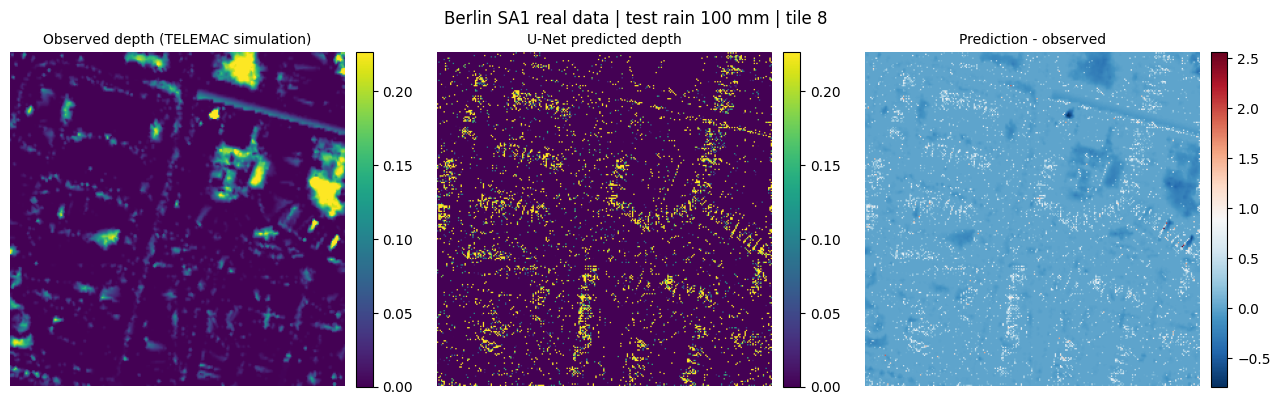


=== PHASE 4 FINISHED ===
OK berlin_phase4_unet_best.keras (89.22 MiB)
OK berlin_phase4_history.csv (0.0 MiB)
OK berlin_phase4_metrics.csv (0.0 MiB)
OK berlin_phase4_summary.json (0.0 MiB)
OK berlin_phase4_normalization.json (0.0 MiB)
OK berlin_phase4_patch_manifest.csv (0.0 MiB)
OK berlin_phase4_real_prediction.png (0.64 MiB)
PASS if all files above show OK and the test predictions are finite.


In [14]:
import matplotlib.pyplot as plt
rec,actual,predicted,valid=PREVIEWS['test']
actual_plot=np.where(valid,actual,np.nan)
predicted_plot=np.where(valid,predicted,np.nan)
vmax=max(float(np.nanpercentile(actual_plot,99)),0.1)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,img,title in zip(axes,
         [actual_plot,predicted_plot,predicted_plot-actual_plot],
         ['Observed depth (TELEMAC simulation)','U-Net predicted depth','Prediction - observed']):
    im=ax.imshow(img,cmap='viridis' if 'Prediction -' not in title else 'RdBu_r',
                 vmin=None if 'Prediction -' in title else 0,
                 vmax=None if 'Prediction -' in title else vmax)
    ax.set_title(title,fontsize=10);ax.axis('off')
    fig.colorbar(im,ax=ax,fraction=0.045,pad=0.03)
fig.suptitle(f"Berlin SA1 real data | test rain {rec['rain_mm']} mm | tile {rec['tile_id']}")
fig.tight_layout()
fig.savefig(OUT/'berlin_phase4_real_prediction.png',dpi=140,bbox_inches='tight')
plt.show();plt.close(fig)

summary={
 'status':'REAL_BERLIN_UNET_ENGINEERING_PILOT_NOT_PAPER_REPRODUCTION_NOT_HCMC_TRANSFER',
 'source_record':'7221058','paper_doi':'10.5194/nhess-23-809-2023',
 'architecture_source':'Code/Convolutional neural network/U-Net.SA1&2.ipynb',
 'architecture':'original-style U-Net, 13 input channels and 1 linear depth output',
 'features_in_order':FEATURE_LABELS,'study_area':'SA1',
 'grid_crs':str(GRID['crs']),'grid_resolution':list(GRID['resolution']),
 'assumed_crs_source_files':assumed_crs,'train_rain_mm':list(TRAIN_RAIN),
 'validation_rain_mm':VAL_RAIN,'test_rain_mm':TEST_RAIN,
 'train_tile_ids':train_ids,'heldout_tile_ids':heldout_ids,
 'smoke_only':SMOKE_ONLY,'epochs':EPOCHS,'batch_size':BATCH_SIZE,
 'model_parameters':int(model.count_params()),'tensorflow':tf.__version__,
 'training_seconds':round(float(training_seconds),2),
 'train_patches':len(RECORDS['train']),'validation_patches':len(RECORDS['validation']),
 'test_patches':len(RECORDS['test']),
 'adaptations_vs_source':['pre-aligned SA1 raster crops','masked NoData pixels','train-only median/IQR input scaling and clipping','sampling 256x256 patches from Phase 3 spatial tiles','limited rainfall scenarios','Adam lr=1e-4','negative prediction clipping during evaluation'],
 'limitations':['pilot, not published reproduction','validation and test share spatial tiles, but have different rainfall events','spatial raster CRS may be provisionally assumed for listed files','water-depth units assumed meters pending original metadata verification','does not assess transfer to Ho Chi Minh City','not directly comparable to Phase 3 RF pixel-sampled metrics'],
 'results':EVAL_RESULTS
}
(OUT/'berlin_phase4_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
print('\n=== PHASE 4 FINISHED ===')
for name in ['berlin_phase4_unet_best.keras','berlin_phase4_history.csv',
             'berlin_phase4_metrics.csv','berlin_phase4_summary.json',
             'berlin_phase4_normalization.json','berlin_phase4_patch_manifest.csv',
             'berlin_phase4_real_prediction.png']:
    p=OUT/name
    print('OK' if p.is_file() else 'MISSING',p.name,
          '('+str(round(p.stat().st_size/2**20,2))+' MiB)' if p.is_file() else '')
print('PASS if all files above show OK and the test predictions are finite.')


## What to send back / what Phase 4 proves

Send **(1)** `berlin_phase4_metrics.csv`, **(2)** `berlin_phase4_summary.json`, and **(3)** `berlin_phase4_real_prediction.png` (or their printed outputs). Optionally save `.keras` and normalization JSON for subsequent HCMC experiments. The `.keras` file alone is **not enough for HCMC inference**: you must apply the **exact 13-channel feature order and normalization**, preserve 256×256 spatial alignment, and map missing/nodata pixels correctly.

**Engineering PASS** means: on Kaggle we loaded genuine Berlin GeoTIFF inputs, created 13-channel patches and true labels, ran a full U-Net forward/backward step, saved weights and predicted full real-data depth maps. It does **not** mean high accuracy or Berlin→HCMC transfer performance.

**Future HCMC transfer plan:** choose local feature sources matching each of Berlin's 12 *semantic* variables and rainfall units, inspect CRS/resolution/NoData and target labels, evaluate Berlin-trained weights **without training on HCMC first** (zero-shot), then optionally fine-tune with labeled HCMC data. Compare against a locally trained RF and the unchanged Berlin baseline on a fixed local test split. Document any proxies or unavailable features. Keep normalization from Berlin for zero-shot; do not refit normalization on HCMC without explicitly labeling it as domain adaptation.

**Do not switch Accelerator from CPU to GPU until you have preserved input files; Kaggle restarts the session.**

**Before leaving Kaggle:** save a notebook version with output files or create a Kaggle Dataset from `/kaggle/working/berlin_sa1_aligned_predictors` and `/kaggle/working/berlin_sa1_targets`. Scratch files under `/kaggle/tmp` are not durable. Avoid blindly selecting Save & Run All after the cached-data session ends.

In [15]:

from pathlib import Path
import shutil
import kagglehub

WORK = Path("/kaggle/working")
BACKUP = WORK / "berlin_phase4_backup"

files = [
    "berlin_phase4_unet_best.keras",
    "berlin_phase4_normalization.json",
    "berlin_phase4_metrics.csv",
    "berlin_phase4_summary.json",
    "berlin_phase4_real_prediction.png",
]

# Check all required files
missing = [f for f in files if not (WORK / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

BACKUP.mkdir(parents=True, exist_ok=True)

for name in files:
    shutil.copy2(WORK / name, BACKUP / name)
    print("READY:", name)

# Save results to Kaggle Datasets
handle = "longltrnhong/berlin-phase4-unet-results"

kagglehub.dataset_upload(handle, str(BACKUP))

print("\nBACKUP UPLOAD FINISHED")
print("https://www.kaggle.com/datasets/" + handle)


READY: berlin_phase4_unet_best.keras
READY: berlin_phase4_normalization.json
READY: berlin_phase4_metrics.csv
READY: berlin_phase4_summary.json
READY: berlin_phase4_real_prediction.png
Uploading Dataset https://kaggle.com/datasets/longltrnhong/berlin-phase4-unet-results ...
Starting upload for file /kaggle/working/berlin_phase4_backup/berlin_phase4_normalization.json

Uploading: 100%|██████████| 1.14k/1.14k [00:01<00:00, 678B/s]

Upload successful: /kaggle/working/berlin_phase4_backup/berlin_phase4_normalization.json (1KB)
Starting upload for file /kaggle/working/berlin_phase4_backup/berlin_phase4_unet_best.keras



Uploading: 100%|██████████| 93.6M/93.6M [00:07<00:00, 12.6MB/s]

Upload successful: /kaggle/working/berlin_phase4_backup/berlin_phase4_unet_best.keras (89MB)
Starting upload for file /kaggle/working/berlin_phase4_backup/berlin_phase4_real_prediction.png



Uploading: 100%|██████████| 668k/668k [00:01<00:00, 351kB/s]

... (2 outputs left out)

Upload successful: /kaggle/working/berlin_phase4_backup/berlin_phase4_metrics.csv (505B)
Starting upload for file /kaggle/working/berlin_phase4_backup/berlin_phase4_summary.json



Uploading: 100%|██████████| 2.97k/2.97k [00:01<00:00, 1.78kB/s]

Upload successful: /kaggle/working/berlin_phase4_backup/berlin_phase4_summary.json (3KB)


Your dataset has been created.
Files are being processed...
See at: https://kaggle.com/datasets/longltrnhong/berlin-phase4-unet-results

BACKUP UPLOAD FINISHED
https://www.kaggle.com/datasets/longltrnhong/berlin-phase4-unet-results
